<center><h1>Shelar_Kartik_HW6</h1></center>

Name: Kartik Shelar
<br>
Github Username: kartikshelar
<br>
USC ID: 4217403571

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score, accuracy_score
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the APS Failure data

In [2]:
# The first 20 lines of each file are a licence header; missing values are "na"
train_data = pd.read_csv(
    "Homework 6 Data/aps_failure_training_set.csv", skiprows=20, na_values="na"
)
test_data = pd.read_csv(
    "Homework 6 Data/aps_failure_test_set.csv", skiprows=20, na_values="na"
)

print("Training shape:", train_data.shape)
print("Test shape:", test_data.shape)

Training shape: (60000, 171)
Test shape: (16000, 171)


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

**Common techniques for missing data (data imputation)**

- **Deletion:** drop rows (listwise) or columns with missing values. It is simple, but it throws away information and can bias the data if values are not missing completely at random.
- **Simple statistic imputation:** replace each missing value with the column mean, median, or mode, or with a constant such as 0 (sometimes with a "was missing" indicator column).
- **Hot-deck / k-nearest-neighbours imputation:** fill in a value using the most similar observations.
- **Regression and model-based imputation:** predict the missing feature from the other features. Examples are regression imputation, MICE (iterative / chained equations), EM, and tree-based imputers such as missForest.
- **Algorithms that handle missing values directly:** XGBoost, for example, learns a default direction at each split for missing values.

**Why I did not use deletion**

About 8.3% of all entries in the training set are missing. 99% of the rows have at least one missing value, so dropping rows would remove almost the whole data set, including most of the 1,000 positive cases. 8 columns are more than 50% missing, and the worst, `br_000`, is 82%.

**What I used: median imputation**

Every missing value is replaced by the median of its column. The features are very skewed with huge outliers (some values are around 8.6 billion), so the mean would sit far from a typical value. The median holds up against this and is cheap to compute on 60,000 x 170 values. The imputer is fit on the training set and the same medians are applied to the test set, so no test information leaks in. In (e) and (f), the imputer is part of the cross-validation pipeline and is refit on the training folds only. Median imputation shrinks the variance of a feature and ignores relationships between features.

In [3]:
X_train = train_data.drop(columns="class")
y_train = train_data["class"].map({"neg": 0, "pos": 1})
X_test = test_data.drop(columns="class")
y_test = test_data["class"].map({"neg": 0, "pos": 1})

# Median imputation: the medians are learned on the training set only
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)

#### (ii) Calculate the coefficient of variation

In [4]:
cv = X_train.std(ddof=1) / X_train.mean()

cv_results = cv.to_frame(name="Coefficient of Variation")
print(cv_results)
print("Number of features:", len(cv_results))

        Coefficient of Variation
aa_000                  2.450938
ab_000                 10.383494
ac_000                  2.310241
ad_000                244.322816
ae_000                 24.200137
...                          ...
ee_007                  5.012754
ee_008                  3.259079
ee_009                  5.691612
ef_000                 49.366659
eg_000                 42.481747

[170 rows x 1 columns]
Number of features: 170


#### (iii) Plot a correlation matrix

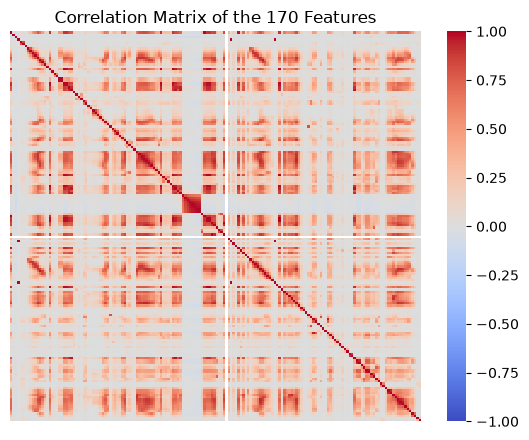

Correlation matrix shape: (170, 170)


In [5]:
correlation_matrix = X_train.corr()

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            xticklabels=False, yticklabels=False)
plt.title("Correlation Matrix of the 170 Features")
plt.tight_layout()
plt.show()

print("Correlation matrix shape:", correlation_matrix.shape)

#### (iv) Make scatter plots and box plots

In [6]:
number_of_features = int(np.sqrt(X_train.shape[1]))  # floor(sqrt(170)) = 13
top_features = cv.nlargest(number_of_features).index.tolist()

print(f"The {number_of_features} features with the highest CV:")
print(cv.loc[top_features].round(2).to_string())

The 13 features with the highest CV:
cf_000    244.89
co_000    244.51
ad_000    244.32
cs_009    237.93
dh_000    123.22
dj_000    117.49
ag_000     92.92
as_000     87.33
ay_009     84.73
ak_000     80.42
az_009     77.84
ch_000     77.45
au_000     68.88


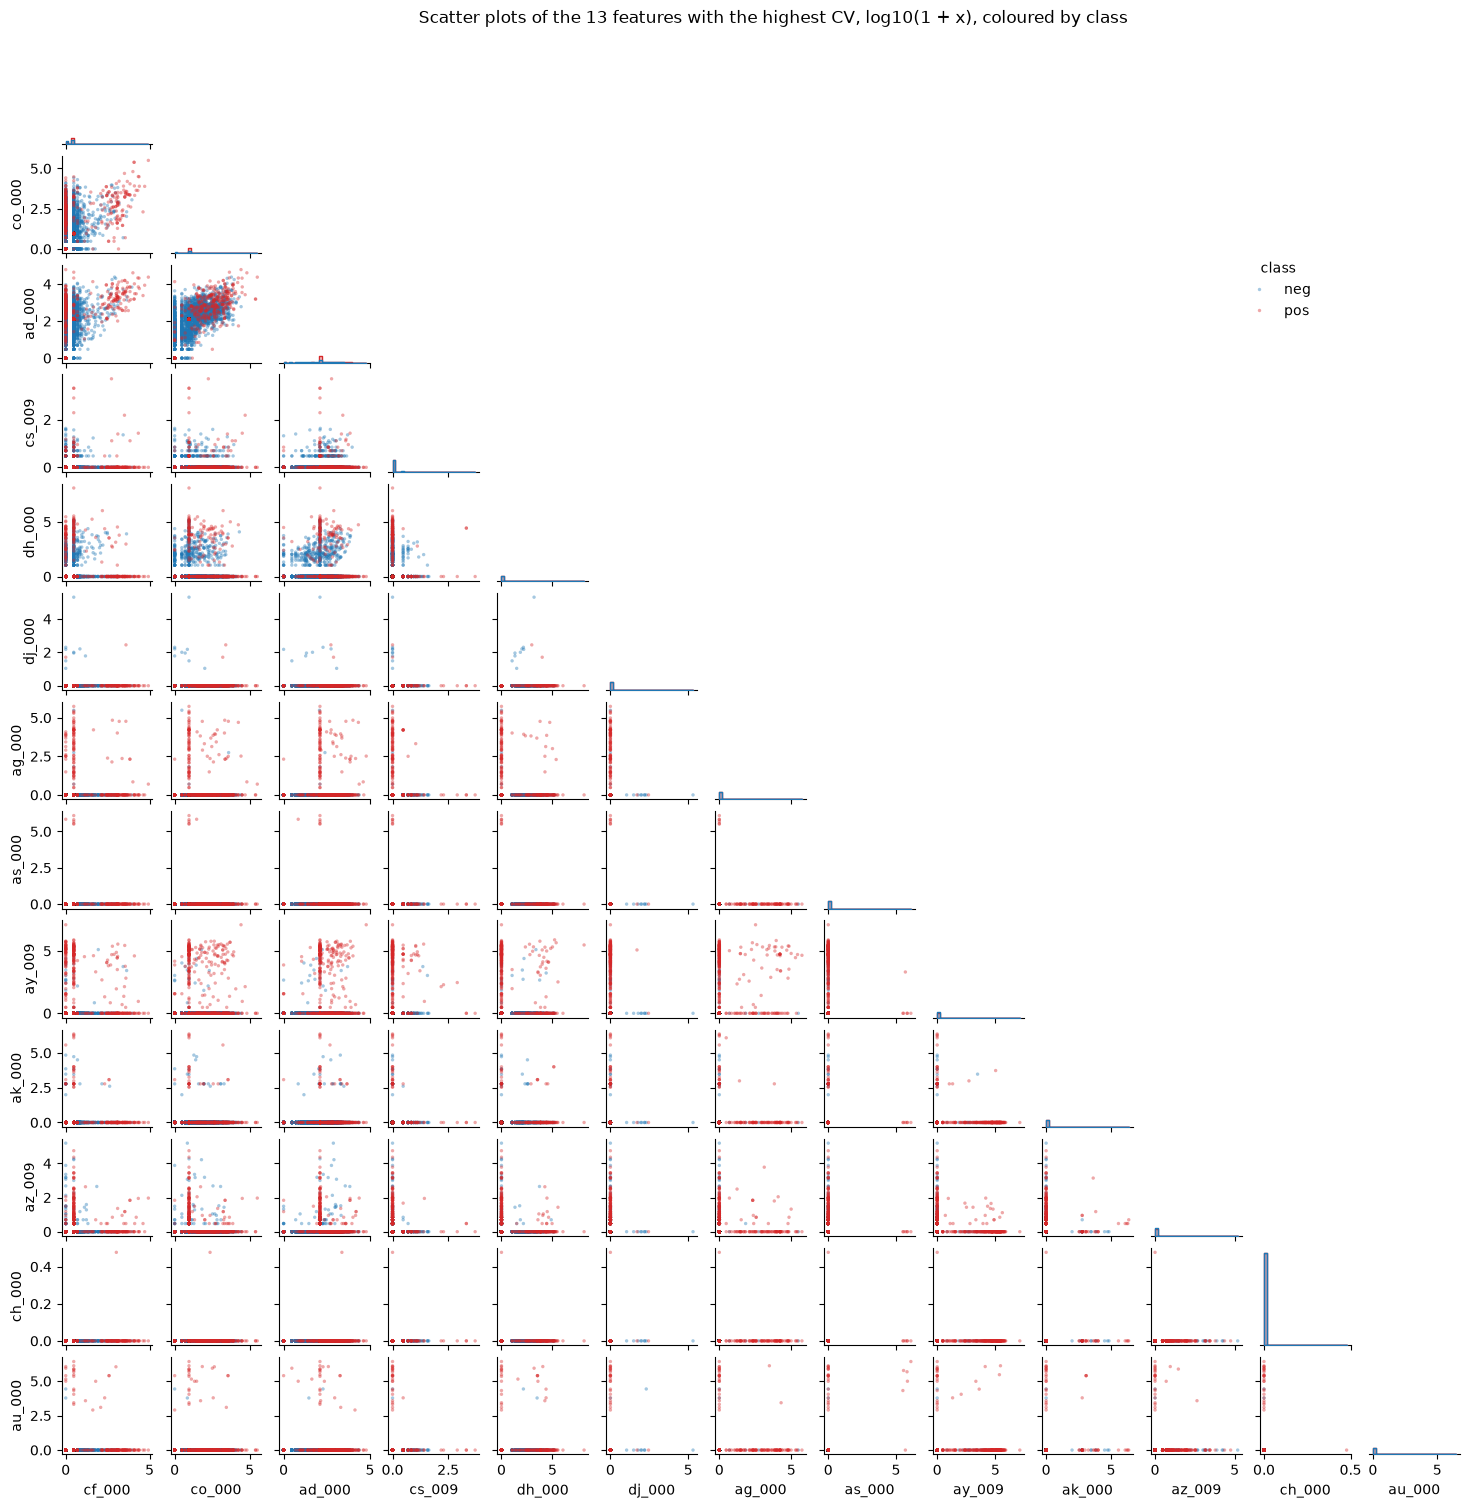

In [7]:
# Scatter plots of every pair of the 13 features, coloured by class.
# The values range from 0 to about 8.6 billion, so the plots use log10(1 + x).
# All 1,000 positives and a random sample of 3,000 negatives keep the rare
# class visible.
plot_data = np.log10(1 + X_train[top_features])
plot_data["class"] = y_train.map({0: "neg", 1: "pos"})
plot_sample = pd.concat([
    plot_data[plot_data["class"] == "neg"].sample(3000, random_state=42),
    plot_data[plot_data["class"] == "pos"]
])

grid = sns.pairplot(
    plot_sample,
    vars=top_features,
    hue="class",
    hue_order=["neg", "pos"],
    palette={"neg": "tab:blue", "pos": "tab:red"},
    corner=True,  # the upper triangle repeats the lower one
    diag_kind="hist",
    diag_kws={"bins": 30, "element": "step", "stat": "density",
              "common_norm": False},
    plot_kws={"s": 6, "alpha": 0.4, "linewidth": 0},
    height=1.15
)
sns.move_legend(grid, "upper right", bbox_to_anchor=(0.85, 0.85), title="class")
grid.figure.suptitle(
    "Scatter plots of the 13 features with the highest CV, log10(1 + x), "
    "coloured by class",
    y=1.01
)
plt.show()

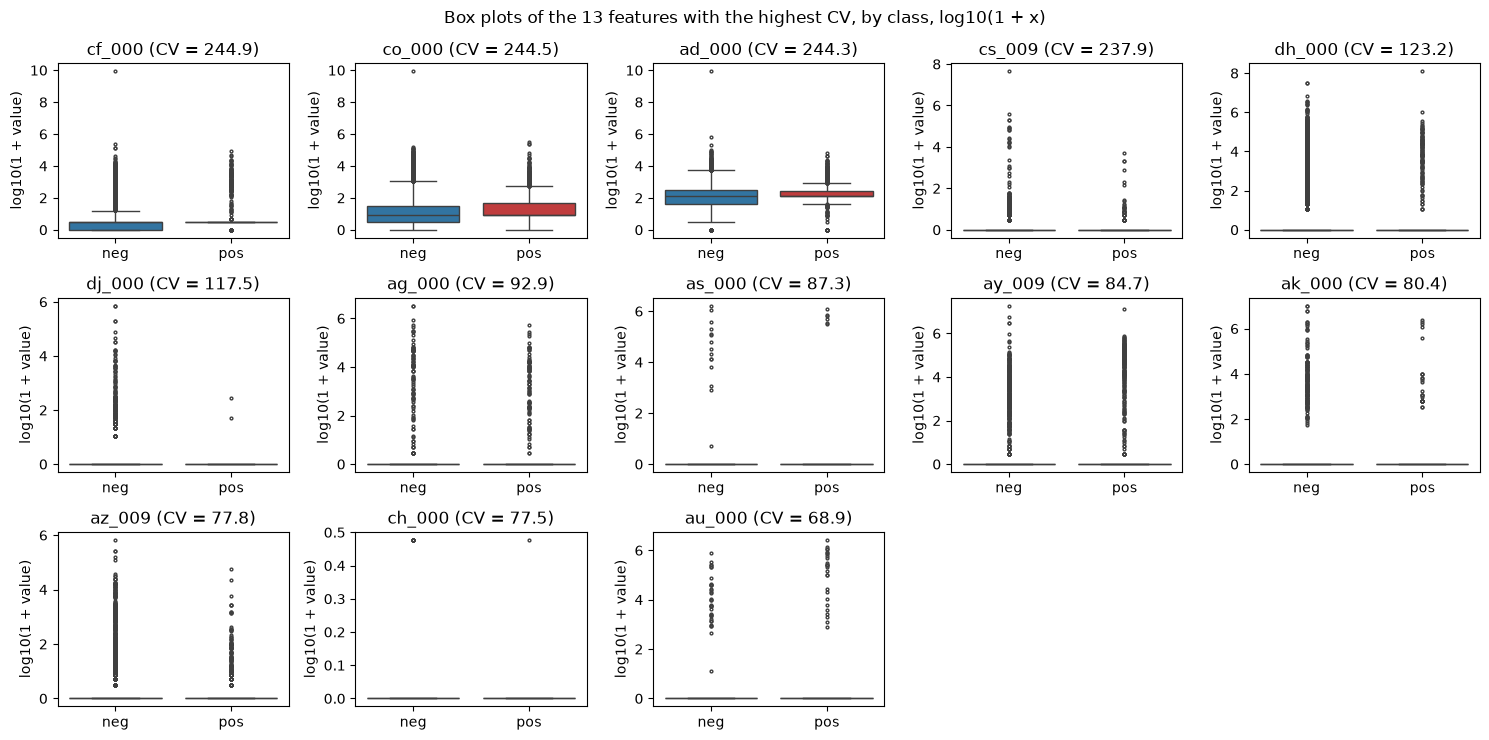

In [8]:
# Box plots of the same 13 features, one box per class
class_labels = y_train.map({0: "neg", 1: "pos"})

fig, axes = plt.subplots(3, 5, figsize=(15, 7.5))
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(
        x=class_labels,
        y=np.log10(1 + X_train[feature]),
        order=["neg", "pos"],
        hue=class_labels,
        palette={"neg": "tab:blue", "pos": "tab:red"},
        fliersize=2,
        ax=ax
    )
    ax.set_title(f"{feature} (CV = {cv[feature]:.1f})")
    ax.set_xlabel("")
    ax.set_ylabel("log10(1 + value)")

for ax in axes.flat[len(top_features):]:
    ax.axis("off")

fig.suptitle(
    "Box plots of the 13 features with the highest CV, by class, log10(1 + x)"
)
plt.tight_layout()
plt.show()

(The scatter plots show all 1,000 positives and a random sample of 3,000 negatives. The box plots use all 60,000 training rows. Both use log10(1 + x) because the values range from 0 to about 8.6 billion.)

The plots only support weak conclusions. For 10 of the 13 features, more than 88% of the values are 0 (over 99% for seven), so the boxes of both classes collapse onto zero. Positives (red) tend to sit at large values of the related group `cf_000`, `co_000`, and `ad_000`, and among the non-zero values of `ag_000`, `as_000`, `ay_009`, and `au_000`. The classes overlap almost everywhere, so there is no clean boundary.

A high CV mostly comes from one extreme value. `cf_000`, `co_000`, and `ad_000` share the value 8.58 billion, which gives a CV of about 245 (the square root of 60,000). The plots can't show significance. The positive rate among the non-zero rows is 49.5% for `ag_000` but only 1.68% (the base rate) for `ad_000`, even though `ad_000` has the larger CV.

#### (v) Is this data set imbalanced?

In [9]:
class_counts = train_data["class"].value_counts()

print(pd.DataFrame({
    "count": class_counts,
    "percent": (100 * class_counts / class_counts.sum()).round(2)
}))

       count  percent
class                
neg    59000    98.33
pos     1000     1.67


Yes, the training dataset is highly imbalanced. Negative observations represent approximately 98.33%, while positive observations represent only 1.67% of the data.

### (c) Train a random forest

In [10]:
def evaluate(model, X_tr, X_te):
    """Confusion matrix, misclassification rate, AUC and ROC on both sets."""
    results = {}
    for name, X_, y_ in [("train", X_tr, y_train), ("test", X_te, y_test)]:
        predictions = model.predict(X_)
        probabilities = model.predict_proba(X_)[:, 1]
        results[name] = {
            "confusion": confusion_matrix(y_, predictions),
            "error": 1 - accuracy_score(y_, predictions),
            "auc": roc_auc_score(y_, probabilities),
            "roc": roc_curve(y_, probabilities)[:2]
        }
    return results


def report(results, title):
    """Print confusion matrices, errors and AUCs; plot both ROC curves."""
    for name in ("train", "test"):
        r = results[name]
        print(f"{name.capitalize()} confusion matrix [[TN, FP], [FN, TP]]:")
        print(r["confusion"])
        print(f"{name.capitalize()} misclassification rate: {r['error']:.6f}, "
              f"AUC: {r['auc']:.6f}\n")

    plt.figure(figsize=(3.8, 2.7))
    for name in ("train", "test"):
        fpr, tpr = results[name]["roc"]
        label = f"{name.capitalize()} (AUC = {results[name]['auc']:.4f})"
        plt.plot(fpr, tpr, label=label)
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

OOB error estimate: 0.005817

Train confusion matrix [[TN, FP], [FN, TP]]:
[[59000     0]
 [    0  1000]]
Train misclassification rate: 0.000000, AUC: 1.000000

Test confusion matrix [[TN, FP], [FN, TP]]:
[[15606    19]
 [  104   271]]
Test misclassification rate: 0.007687, AUC: 0.994306



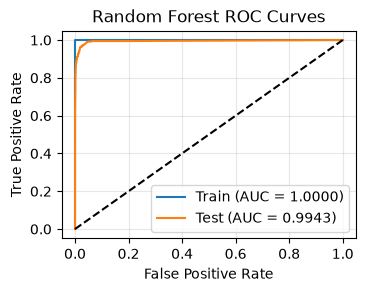

In [11]:
# No compensation for the class imbalance
rf = RandomForestClassifier(
    n_estimators=500, oob_score=True, random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)
rf_results = evaluate(rf, X_train, X_test)

print(f"OOB error estimate: {1 - rf.oob_score_:.6f}\n")
report(rf_results, "Random Forest ROC Curves")

The random forest (500 trees, no compensation for imbalance) fits the training data perfectly. Training error is 0 and training AUC is 1.0. On the test set the error is about 0.77% (19 false positives and 104 false negatives) with an AUC of 0.9943.

The out-of-bag (OOB) error is about 0.58%, close to the test error of 0.77% but slightly lower. That makes sense because the test set has more positives (375 of 16,000, or 2.3%) than the training set (1.7%), which makes it a little harder. So OOB error is a reasonable estimate of test error here, and it needs no separate validation set.

The classifier is accurate overall but misses many positive cases. It finds only 271 of the 375 test failures (recall of about 72%). Accuracy hides this because 98% of the data is negative.

### (d) Research class imbalance in random forest

Common ways to address class imbalance in random forests:

- **Class weights (cost-sensitive learning):** give errors on the minority class a larger weight, so the splits (Gini impurity) and the majority vote in the leaves pay more attention to the rare class. In scikit-learn, `class_weight="balanced"` sets the weights inversely proportional to class frequencies. `class_weight="balanced_subsample"` recomputes them inside every bootstrap sample.
- **Balanced Random Forest (Chen, Liaw and Breiman, 2004):** each tree is trained on a balanced bootstrap sample, drawn by taking the same number of cases from each class (down-sampling the majority class).
- **Resampling the data:** over-sample the minority class (for example with SMOTE) or under-sample the majority class before training.
- **Moving the decision threshold:** predict positive when the predicted probability is above a value smaller than 0.5.

**What I used:** class weights with `class_weight="balanced_subsample"` and 500 trees (the same as in (c)), plus `min_samples_leaf=5`. The leaf-size limit is needed. When trees grow until every leaf is pure, each leaf holds only one class and the class weights have almost no effect. In a preliminary run without the limit, the weighted forest missed more failures (158 false negatives) than the unweighted one. With at least 5 samples per leaf, the leaves can hold a mix of classes, so the weights change the predictions.

OOB error estimate: 0.008217

Train confusion matrix [[TN, FP], [FN, TP]]:
[[58835   165]
 [    1   999]]
Train misclassification rate: 0.002767, AUC: 0.999911

Test confusion matrix [[TN, FP], [FN, TP]]:
[[15545    80]
 [   70   305]]
Test misclassification rate: 0.009375, AUC: 0.992711



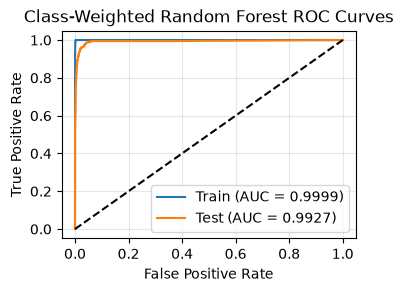

In [12]:
# Class weights recomputed in every bootstrap sample; min_samples_leaf=5 so that
# the leaves are not all pure and the weights can affect the votes
balanced_rf = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced_subsample",
    min_samples_leaf=5,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
balanced_rf.fit(X_train, y_train)
balanced_results = evaluate(balanced_rf, X_train, X_test)

print(f"OOB error estimate: {1 - balanced_rf.oob_score_:.6f}\n")
report(balanced_results, "Class-Weighted Random Forest ROC Curves")

**Comparison of the two random forests (test set, 15,625 negatives and 375 positives):**

| | Plain RF | Class-weighted RF |
|---|---|---|
| False positives | 19 | 80 |
| False negatives | 104 | 70 |
| Recall (positives found) | 72.3% | 81.3% |
| Precision | 93.4% | 79.2% |
| Test error | 0.77% | 0.94% |
| OOB error | 0.58% | 0.82% |
| Test AUC | 0.9943 | 0.9927 |
| Training error | 0.00% | 0.28% |

Compensating for the imbalance made the forest find more of the rare failures. False negatives dropped from 104 to 70, so recall rose from 72% to 81%. The cost is more false alarms (false positives rose from 19 to 80), which lowers precision and slightly raises the overall error rate. That is the expected trade-off, because the weighted forest predicts the minority class more often. The AUC is almost the same (0.9943 vs 0.9927), so both models rank cases about equally well, and the difference is mainly where the 0.5 cutoff falls. The training fit is no longer perfect, because larger leaves and weighting stop the trees from memorising every training point. The OOB estimate of the weighted forest is again close to its test error (0.82% vs 0.94%).

The overall error rate is a poor measure here because 98% of the data is negative. Using the costs from the data set description (10 per unnecessary check, 500 per missed faulty truck), the plain forest costs 19 x 10 + 104 x 500 = 52,190 and the weighted forest costs 80 x 10 + 70 x 500 = 35,800. The weighted forest is better for this application despite its higher misclassification rate.

### (e) XGBoost and model trees

I fit the model with XGBoost and no compensation for the class imbalance (`scale_pos_weight=1`). I chose the L1 regularisation term α (`reg_alpha`, an L1 penalty on the leaf weights of the boosted trees, with the logistic loss) by 5-fold stratified cross-validation over {0, 0.001, 0.01, 0.1, 1, 10, 100}. The score is accuracy (CV error = 1 - accuracy). The median imputer and XGBoost sit in one pipeline, so the imputer is refit on the training folds of every CV split. Then I compare the CV error of the selected model with its test error.

In [13]:
# Raw features (with missing values): the imputer is part of the pipeline,
# so it is refit on the training folds of every CV split
X_train_raw = train_data.drop(columns="class")
X_test_raw = test_data.drop(columns="class")

alpha_values = [0, 0.001, 0.01, 0.1, 1, 10, 100]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def tune_xgboost(smote):
    """Choose reg_alpha by 5-fold CV for imputer -> (SMOTE) -> XGBoost."""
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if smote:
        steps.append(("smote", SMOTE(random_state=42)))
    steps.append(("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        tree_method="hist",
        scale_pos_weight=1,  # no compensation inside XGBoost
        random_state=42,
        n_jobs=1
    )))

    search = GridSearchCV(
        Pipeline(steps),
        param_grid={"xgb__reg_alpha": alpha_values},
        scoring="accuracy",
        cv=cv,
        n_jobs=4  # limits memory use: each worker holds a copy of the data
    )
    search.fit(X_train_raw, y_train)

    cv_table = pd.DataFrame({
        "alpha": alpha_values,
        "mean CV error": 1 - search.cv_results_["mean_test_score"]
    })
    print(cv_table.to_string(index=False, float_format="{:.6f}".format))

    best_alpha = search.best_params_["xgb__reg_alpha"]
    cv_error = 1 - search.best_score_
    print(f"\nBest alpha: {best_alpha}, 5-fold CV error: {cv_error:.6f}")
    return search.best_estimator_, cv_error

     alpha  mean CV error
  0.000000       0.005767
  0.001000       0.005833
  0.010000       0.005683
  0.100000       0.005683
  1.000000       0.005750
 10.000000       0.007383
100.000000       0.011067

Best alpha: 0.01, 5-fold CV error: 0.005683


Test error: 0.006437, |CV - test| error: 0.000754

Train confusion matrix [[TN, FP], [FN, TP]]:
[[58999     1]
 [   33   967]]
Train misclassification rate: 0.000567, AUC: 0.999902

Test confusion matrix [[TN, FP], [FN, TP]]:
[[15611    14]
 [   89   286]]
Test misclassification rate: 0.006437, AUC: 0.995379



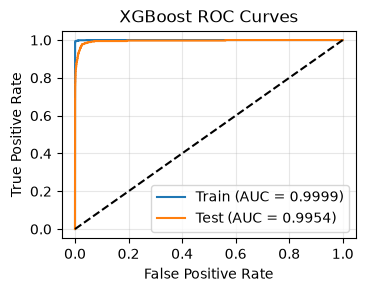

In [14]:
xgb_model, xgb_cv_error = tune_xgboost(smote=False)
xgb_results = evaluate(xgb_model, X_train_raw, X_test_raw)

xgb_test_error = xgb_results["test"]["error"]
xgb_gap = abs(xgb_cv_error - xgb_test_error)
print(f"Test error: {xgb_test_error:.6f}, |CV - test| error: {xgb_gap:.6f}\n")
report(xgb_results, "XGBoost ROC Curves")

Cross-validation selects α = 0.01 (α = 0.1 gives the same CV error). The CV error is nearly flat for α ≤ 1 (between 0.568% and 0.583%) and only gets worse for large values (0.74% at α = 10, 1.11% at α = 100). So the L1 penalty makes almost no difference on this data.

The 5-fold CV error (0.568%) is close to the test error (0.644%), a gap of 0.08 percentage points, so cross-validation estimates the test error well. As with the OOB error in (c), the estimate is slightly lower than the test error because the test set has more positives (2.3% against 1.7%). The model fits the training data almost perfectly (training error 0.057%, AUC 0.9999) and has a test AUC of 0.9954. Like the plain random forest, it misses many failures: 89 of the 375 test positives are false negatives (recall 76.3%), against only 14 false positives.

### (f) Use SMOTE to pre-process your data

SMOTE creates synthetic positives by interpolating between a positive observation and one of its 5 nearest positive neighbours. It is applied to the whole training set, not a down-sampled version. On the 60,000 training rows it adds 58,000 synthetic positives (59,000 + 59,000 points).

For cross-validation, SMOTE is applied only to the training part of each fold. The imputer, SMOTE, and XGBoost sit in one `imblearn` pipeline, so in every fold they are fit on the training folds only, and the validation fold keeps its original, imbalanced distribution. Applying SMOTE to the whole training set before cross-validation would put synthetic points built from the validation observations into the training folds, and the CV error would come out too optimistic. All errors, confusion matrices, and AUCs below are computed on the original, non-resampled data.

     alpha  mean CV error
  0.000000       0.009183
  0.001000       0.009233
  0.010000       0.009233
  0.100000       0.009350
  1.000000       0.009217
 10.000000       0.010633
100.000000       0.018517

Best alpha: 0, 5-fold CV error: 0.009183


Test error: 0.008813, |CV - test| error: 0.000371

Train confusion matrix [[TN, FP], [FN, TP]]:
[[58816   184]
 [   32   968]]
Train misclassification rate: 0.003600, AUC: 0.999383

Test confusion matrix [[TN, FP], [FN, TP]]:
[[15533    92]
 [   49   326]]
Test misclassification rate: 0.008813, AUC: 0.994701



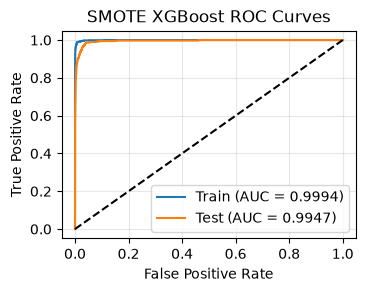

In [15]:
# SMOTE is inside the pipeline, so it only resamples the training folds
smote_model, smote_cv_error = tune_xgboost(smote=True)
smote_results = evaluate(smote_model, X_train_raw, X_test_raw)

smote_test_error = smote_results["test"]["error"]
smote_gap = abs(smote_cv_error - smote_test_error)
print(f"Test error: {smote_test_error:.6f}, |CV - test| error: {smote_gap:.6f}\n")
report(smote_results, "SMOTE XGBoost ROC Curves")

**Comparison of the uncompensated and SMOTE models (test set, 15,625 negatives and 375 positives):**

| | Uncompensated XGBoost | SMOTE XGBoost |
|---|---|---|
| Selected $\alpha$ | 0.01 | 0 |
| 5-fold CV error | 0.57% | 0.92% |
| Test error | 0.64% | 0.88% |
| Test AUC | 0.9954 | 0.9947 |
| False positives | 14 | 92 |
| False negatives | 89 | 49 |
| Recall | 76.3% | 86.9% |
| Cost (10 x FP + 500 x FN) | 44,640 | 25,420 |

SMOTE makes the model find more failures: the false negatives drop from 89 to 49 and the recall rises from 76% to 87%. The price is more false alarms (14 to 92), so the misclassification rate rises slightly (0.64% to 0.88%). The AUC is almost unchanged (0.9954 against 0.9947), so the ranking quality is the same and SMOTE mainly moves the decision threshold towards the positive class. Cross-validation selects $\alpha = 0$ for the SMOTE model, and its CV error (0.92%) agrees well with its test error (0.88%), as it should when SMOTE is applied inside the folds. The uncompensated model has the lower error rate, but with the cost of the data set description (500 per missed failure, 10 per false alarm) the SMOTE model is much cheaper, 25,420 against 44,640, so compensating for the imbalance is worthwhile here.

## 2. ISLR 6.6.3

(a) As we increase s from 0, the training RSS will:

iv. Steadily decrease.
As $s$ increases from 0, the constraint set $\sum_{j=1}^p \vert{}\beta_j\vert{} \leq s$ expands. Minimizing the residual sum of squares over a larger feasible region allows the model to fit the training data more closely, steadily decreasing the training RSS until $s$ is large enough to contain the unconstrained ordinary least squares (OLS) solution.

(b) Repeat (a) for test RSS:

ii. Decrease initially, and then eventually start increasing in a U shape.
At $s = 0$, all slope coefficients are constrained to zero, yielding a rigid, underfit model with high bias and high test RSS. Increasing $s$ initially allows the model to capture the true underlying relationship, reducing test RSS. As $s$ becomes very large, the model gains too much flexibility and begins overfitting noise in the training set (high variance), causing test RSS to increase again in a characteristic U-shaped curve.

(c) Repeat (a) for variance.:

iii. Steadily increase.
When $s = 0$, the coefficients are fixed at 0, giving zero variance across different training datasets. As $s$ increases, the constraint on the coefficients is relaxed, allowing them to adapt more strongly to the specific training sample. This higher flexibility increases the sensitivity of the estimates to sample variations, steadily increasing the model's variance.

(d) Repeat (a) for (squared) bias.:

iv. Steadily decrease.
At $s = 0$, the model is heavily constrained, leading to high estimation bias. As $s$ increases, the model is granted more freedom to estimate non-zero coefficient values and model the true relationship between the predictors and response, causing the squared bias to steadily decrease.

(e) Repeat (a) for the irreducible error.:

v. Remain constant.
The irreducible error reflects the noise inherent to the data-generating process $\text{Var}(\epsilon)$. Because it is a fundamental property of the underlying population rather than the model, it is independent of the choice of regularization parameter $s$.

## 3. ISLR 6.6.5

(a) Write out the ridge regression optimization problem in this setting.

Ridge regression minimizes the sum of squared residuals plus an $\ell_2$ regularization penalty:


$$\min_{\beta_1, \beta_2} \left[ \sum_{i=1}^2 (y_i - \beta_1 x_{i1} - \beta_2 x_{i2})^2 + \lambda (\beta_1^2 + \beta_2^2) \right]$$

Given $x_{11} = x_{12} = x_1$, $x_{21} = x_{22} = x_2 = -x_1$, and $y_2 = -y_1$, the residual terms simplify as follows:   

Observation 1 ($i=1$): $(y_1 - \beta_1 x_1 - \beta_2 x_1)^2 = (y_1 - (\beta_1 + \beta_2)x_1)^2$

Observation 2 ($i=2$): $(-y_1 - \beta_1(-x_1) - \beta_2(-x_1))^2 = (-(y_1 - (\beta_1 + \beta_2)x_1))^2 = (y_1 - (\beta_1 + \beta_2)x_1)^2$   

Combining these terms gives the final optimization problem:
   $$\min_{\beta_1, \beta_2} \left[ 2(y_1 - (\beta_1 + \beta_2)x_1)^2 + \lambda (\beta_1^2 + \beta_2^2) \right]$$

(b) Argue that in this setting, the ridge coefficient estimates satisfy $\hat{\beta}_1 = \hat{\beta}_2$:

Let $f(\beta_1, \beta_2) = 2(y_1 - (\beta_1 + \beta_2)x_1)^2 + \lambda (\beta_1^2 + \beta_2^2)$.   

Taking the partial derivatives with respect to $\beta_1$ and $\beta_2$ and setting them equal to zero:

$$\frac{\partial f}{\partial \beta_1} = -4x_1(y_1 - (\beta_1 + \beta_2)x_1) + 2\lambda\beta_1 = 0$$

$$\frac{\partial f}{\partial \beta_2} = -4x_1(y_1 - (\beta_1 + \beta_2)x_1) + 2\lambda\beta_2 = 0$$

Subtracting the second equation from the first:
   $$2\lambda\beta_1 - 2\lambda\beta_2 = 0 \implies 2\lambda(\beta_1 - \beta_2) = 0$$
   
For any $\lambda > 0$, this strictly requires $\hat{\beta}_1 = \hat{\beta}_2$.  

(Alternatively, because $f(\beta_1, \beta_2)$ is strictly convex for $\lambda > 0$ and symmetric with respect to swapping $\beta_1$ and $\beta_2$, its unique global minimum must lie along the line of symmetry $\beta_1 = \beta_2$.)  

(c) Write out the lasso optimization problem in this setting.

Lasso minimizes the sum of squared residuals plus an $\ell_1$ regularization penalty:

$$\min_{\beta_1, \beta_2} \left[ \sum_{i=1}^2 (y_i - \beta_1 x_{i1} - \beta_2 x_{i2})^2 + \lambda (\vert{}\beta_1\vert{} + \vert{}\beta_2\vert{}) \right]$$

Applying the simplified residual terms yields:
   $$\min_{\beta_1, \beta_2} \left[ 2(y_1 - (\beta_1 + \beta_2)x_1)^2 + \lambda (\vert{}\beta_1\vert{} + \vert{}\beta_2\vert{}) \right]$$

(d) Argue that in this setting, the lasso coefficients $\hat{\beta}_1$ and $\hat{\beta}_2$ are not unique — in other words, there are many possible solutions to the optimization problem in (c). Describe these solutions.

Let $s^{\ast} = \hat{\beta}_1 + \hat{\beta}_2$ be the optimal combined coefficient sum. The residual sum of squares (RSS) depends only on the sum $s = \beta_1 + \beta_2$.

For any optimal sum $s^{\ast}$:

**If $s^{\ast} > 0$:** Any pair $(\hat{\beta}_1, \hat{\beta}_2)$ with $\hat{\beta}_1 \ge 0$, $\hat{\beta}_2 \ge 0$, and $\hat{\beta}_1 + \hat{\beta}_2 = s^{\ast}$ gives $\vert{}\hat{\beta}_1\vert{} + \vert{}\hat{\beta}_2\vert{} = \hat{\beta}_1 + \hat{\beta}_2 = s^{\ast}$.

**If $s^{\ast} < 0$:** Any pair $(\hat{\beta}_1, \hat{\beta}_2)$ with $\hat{\beta}_1 \le 0$, $\hat{\beta}_2 \le 0$, and $\hat{\beta}_1 + \hat{\beta}_2 = s^{\ast}$ gives $\vert{}\hat{\beta}_1\vert{} + \vert{}\hat{\beta}_2\vert{} = -(\hat{\beta}_1 + \hat{\beta}_2) = -s^{\ast} = \vert{}s^{\ast}\vert{}$.

Because every point on these line segments yields the exact same RSS value and the exact same $\ell_1$ penalty value, the solution is not unique.

Description of solutions:

- **$s^{\ast} > 0$:** a line segment, containing infinitely many solutions, connecting $(s^{\ast}, 0)$ and $(0, s^{\ast})$ in the first quadrant ($\hat{\beta}_1 + \hat{\beta}_2 = s^{\ast}$ with $\hat{\beta}_1, \hat{\beta}_2 \ge 0$).
- **$s^{\ast} < 0$:** a line segment, containing infinitely many solutions, connecting $(s^{\ast}, 0)$ and $(0, s^{\ast})$ in the third quadrant ($\hat{\beta}_1 + \hat{\beta}_2 = s^{\ast}$ with $\hat{\beta}_1, \hat{\beta}_2 \le 0$).
- **$s^{\ast} = 0$:** a single unique point at $\hat{\beta}_1 = \hat{\beta}_2 = 0$ (when $\lambda$ is large enough to shrink all coefficients to zero).

Geometrically, because the predictors are identical, the RSS contours are parallel lines of constant $\beta_1 + \beta_2$. When the diamond-shaped $\ell_1$ penalty boundary meets these parallel contour lines, it touches along an entire flat edge of the diamond rather than at a single vertex.

## 4. ISLR 8.4.5

1. **Majority vote approach.** With a threshold of 0.5, the four trees with $P(\text{Red}\vert{}X) = 0.1, 0.15, 0.2, 0.2$ predict Green and the six trees with $P(\text{Red}\vert{}X) = 0.55, 0.6, 0.6, 0.65, 0.7, 0.75$ predict Red. Red receives 6 of the 10 votes, so the final classification is **Red**.

2. **Average probability approach.**

The ten probabilities sum to $0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75 = 4.5$, so

$$\bar{P}(\text{Class is Red}\vert{}X) = \frac{4.5}{10} = 0.45$$

The average probability of Red is $0.45 < 0.5$ (equivalently, the average probability of Green is $0.55$), so the final classification is **Green**.

## 5. ISLR 9.7.3

(a) Sketch of the observations: panel (a) of the figure below, which also shows the sketches asked for in (b), (d), (e), (g) and (h).

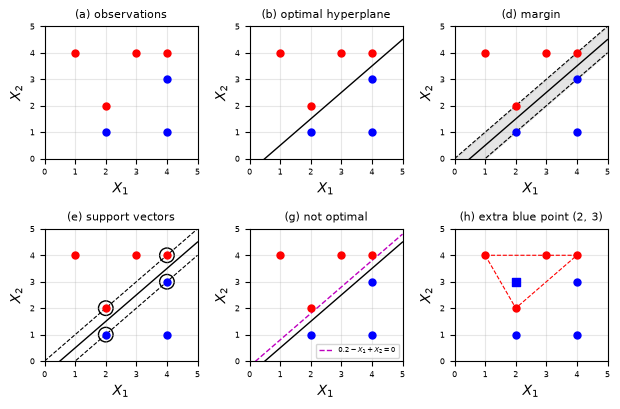

In [16]:
X_red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
X_blue = np.array([[2, 1], [4, 3], [4, 1]])
sv = np.array([[2, 2], [4, 4], [2, 1], [4, 3]])  # support vectors
tri = np.array([[1, 4], [2, 2], [4, 4], [1, 4]])  # triangle of the red points
x = np.linspace(0, 5, 100)
hyper, upper, lower = x - 0.5, x, x - 1  # hyperplane and margin boundaries

fig, axes = plt.subplots(2, 3, figsize=(6.3, 4.2))
titles = ["(a) observations", "(b) optimal hyperplane", "(d) margin",
          "(e) support vectors", "(g) not optimal",
          "(h) extra blue point (2, 3)"]
for ax, title in zip(axes.flat, titles):
    ax.scatter(*X_red.T, color="red", s=25, zorder=5)
    ax.scatter(*X_blue.T, color="blue", s=25, zorder=5)
    ax.set(xlim=(0, 5), ylim=(0, 5), xlabel="$X_1$", ylabel="$X_2$")
    ax.set_title(title, fontsize=8)
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=6)
# (b), (d), (e), (g): hyperplane 0.5 - X1 + X2 = 0
for ax in axes.flat[1:5]:
    ax.plot(x, hyper, "k-", linewidth=1)
# margin boundaries X2 = X1 and X2 = X1 - 1
for ax in (axes[0, 2], axes[1, 0]):
    ax.plot(x, upper, "k--", linewidth=0.8)
    ax.plot(x, lower, "k--", linewidth=0.8)
axes[0, 2].fill_between(x, lower, upper, color="gray", alpha=0.2)
axes[1, 0].scatter(*sv.T, s=110, facecolors="none", edgecolors="black")
axes[1, 1].plot(x, x - 0.2, "m--", linewidth=1, label="$0.2 - X_1 + X_2 = 0$")
axes[1, 1].legend(fontsize=5, loc="lower right")
axes[1, 2].scatter([2], [3], color="blue", marker="s", s=35, zorder=6)
axes[1, 2].plot(*tri.T, "r--", linewidth=0.8)
plt.tight_layout()
plt.show()

(b) The closest red points (2, 2) and (4, 4) lie on the line $X_2 = X_1$ and the closest blue points (2, 1) and (4, 3) on $X_2 = X_1 - 1$; the optimal hyperplane is the line midway between them: $X_2 = X_1 - 0.5$, i.e. $0.5 - X_1 + X_2 = 0$.

(c) Classify to **Red** if $0.5 - X_1 + X_2 > 0$ and to **Blue** otherwise: $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$ (normalised, $\beta_1^2 + \beta_2^2 = 1$: $0.354$, $-0.707$, $0.707$). Check: red (1, 4) gives $3.5 > 0$, blue (4, 1) gives $-2.5 < 0$.

(d) The margin boundaries are the dashed lines $X_2 = X_1$ and $X_2 = X_1 - 1$ (panel (d)); the margin is $M = 0.5/\sqrt{2} \approx 0.354$.

(e) The support vectors are observations 2 (2, 2), 3 (4, 4), 5 (2, 1) and 6 (4, 3), circled in panel (e).

(f) Observation 7 at (4, 1) is at distance $2.5/\sqrt{2} \approx 1.77$ from the hyperplane, far outside the margin ($M \approx 0.35$), so it is not a support vector. The hyperplane depends only on the support vectors, so a slight movement of observation 7 does not change it.

(g) For example $X_2 = X_1 - 0.2$, i.e. $0.2 - X_1 + X_2 = 0$ (panel (g)): it separates the classes, but with a smaller margin ($0.2/\sqrt{2} \approx 0.14$).

(h) A blue observation at (2, 3) (panel (h)) lies inside the triangle formed by the red points (1, 4), (2, 2) and (4, 4), so every line that has all red points on one side also has (2, 3) on that side: the classes are no longer separable.